downloading ucimlrepo<br>
since we will be using a health disease dataset from https://archive.ics.uci.edu/dataset/14/breast+cancer

In [1]:
# Optional: install only if you want to fetch the dataset from UCI online
%pip install ucimlrepo seaborn matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


importing the modules.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from ucimlrepo import fetch_ucirepo

## importing the dataset from the site.

In [3]:
# fetch dataset
breast_cancer = fetch_ucirepo(id=14)

# data (as pandas dataframes)
X = breast_cancer.data.features
Y = breast_cancer.data.targets
df = pd.concat([X, Y], axis=1)

# variable information
print(breast_cancer.variables)

          name     role         type demographic  \
0        Class   Target       Binary         NaN   
1          age  Feature  Categorical         Age   
2    menopause  Feature  Categorical         NaN   
3   tumor-size  Feature  Categorical         NaN   
4    inv-nodes  Feature  Categorical         NaN   
5    node-caps  Feature       Binary         NaN   
6    deg-malig  Feature      Integer         NaN   
7       breast  Feature       Binary         NaN   
8  breast-quad  Feature  Categorical         NaN   
9     irradiat  Feature       Binary         NaN   

                                         description  units missing_values  
0            no-recurrence-events, recurrence-events    NaN             no  
1  10-19, 20-29, 30-39, 40-49, 50-59, 60-69, 70-7...  years             no  
2                                lt40, ge40, premeno    NaN             no  
3  0-4, 5-9, 10-14, 15-19, 20-24, 25-29, 30-34, 3...    NaN             no  
4   0-2, 3-5, 6-8, 9-11, 12-14, 15-17, 18-

In [4]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          286 non-null    str  
 1   menopause    286 non-null    str  
 2   tumor-size   286 non-null    str  
 3   inv-nodes    286 non-null    str  
 4   node-caps    278 non-null    str  
 5   deg-malig    286 non-null    int64
 6   breast       286 non-null    str  
 7   breast-quad  285 non-null    str  
 8   irradiat     286 non-null    str  
 9   Class        286 non-null    str  
dtypes: int64(1), str(9)
memory usage: 22.5 KB
None
        deg-malig
count  286.000000
mean     2.048951
std      0.738217
min      1.000000
25%      2.000000
50%      2.000000
75%      3.000000
max      3.000000


## we will now clean and process the data.

In [5]:
# Check missing values before imputation
display(df.isna().sum().to_frame("missing_count"))
print("Total missing values:", df.isna().sum().sum())

,missing_count
age,0
menopause,0
tumor-size,0
inv-nodes,0
node-caps,8
deg-malig,0
breast,0
breast-quad,1
irradiat,0
Class,0


Total missing values: 9


The raw file uses `?` to represent missing values. `read_csv(..., na_values="?")` converts these to `NaN`. Since these are categorical features, we will impute missing values with each column's mode. This is a simple baseline; for a predictive model, imputation should be fitted on training data only to avoid data leakage.

In [6]:
# Fill missing values in categorical columns with each column's mode
categorical_cols = df.columns.tolist()
for col in categorical_cols:
    if df[col].isna().any():
        mode_value = df[col].mode(dropna=True)[0]
        df[col] = df[col].fillna(mode_value)
        print(f"{col}: missing values filled with mode = {mode_value!r}")

print("Remaining missing values:", int(df.isna().sum().sum()))

node-caps: missing values filled with mode = 'no'
breast-quad: missing values filled with mode = 'left_low'
Remaining missing values: 0


In [7]:
# Confirm that the dataset has no missing values after imputation
display(df.isna().sum().to_frame("missing_count"))

,missing_count
age,0
menopause,0
tumor-size,0
inv-nodes,0
node-caps,0
deg-malig,0
breast,0
breast-quad,0
irradiat,0
Class,0


## Aggregation.

In [8]:
aggregation = df.groupby('Class').agg({
    'deg-malig': 'mean'
})

print(aggregation)

                      deg-malig
Class                          
no-recurrence-events   1.905473
recurrence-events      2.388235


In [9]:
aggregation = df.groupby('menopause').agg({
    'deg-malig': ['mean', 'min', 'max']
})

print(aggregation)

          deg-malig        
               mean min max
menopause                  
ge40       2.093023   1   3
lt40       1.714286   1   3
premeno    2.026667   1   3


#Discretization

In [10]:
# deg-malig is already an ordinal rating from 1 to 3.
malig_map = {1: "Low", 2: "Medium", 3: "High"}
df["malignancy_category"] = df["deg-malig"].map(malig_map)

display(df[["deg-malig", "malignancy_category"]].head())

,deg-malig,malignancy_category
0,3,High
1,2,Medium
2,2,Medium
3,2,Medium
4,2,Medium


#Binarization

In [11]:
df['node_caps_flag'] = (df['node-caps'] == 'yes').astype(int)
df['irradiat_flag'] = (df['irradiat'] == 'yes').astype(int)
df['recurrence'] = (df['Class'] == 'recurrence-events').astype(int)
print(df[['node-caps', 'node_caps_flag', 'irradiat', 'irradiat_flag', 'Class', 'recurrence']].head())

  node-caps  node_caps_flag irradiat  irradiat_flag                 Class  \
0        no               0       no              0  no-recurrence-events   
1        no               0       no              0  no-recurrence-events   
2        no               0       no              0  no-recurrence-events   
3        no               0       no              0  no-recurrence-events   
4        no               0       no              0  no-recurrence-events   

   recurrence  
0           0  
1           0  
2           0  
3           0  
4           0  


#Sampling
selecting a subset of the entire dataset.

In [12]:
# Reproducible simple random sample
sample = df.sample(n=min(100, len(df)), random_state=42)
display(sample.head())
print("Sample shape:", sample.shape)

,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat,Class,malignancy_category,node_caps_flag,irradiat_flag,recurrence
9,40-49,premeno,20-24,0-2,no,2,right,left_up,no,no-recurrence-events,Medium,0,0,0
267,60-69,ge40,20-24,24-26,yes,3,left,left_low,yes,recurrence-events,High,1,1,1
143,40-49,premeno,45-49,0-2,no,2,left,left_low,yes,no-recurrence-events,Medium,0,1,0
212,40-49,premeno,30-34,0-2,no,3,right,right_up,no,recurrence-events,High,0,0,1
227,50-59,premeno,30-34,0-2,no,3,right,left_up,yes,recurrence-events,High,0,1,1


Sample shape: (100, 14)


# 1. Exploratory Data Analysis (EDA)

Start by checking the class balance and how the categorical attributes are distributed. Because this dataset is small and mostly categorical, count plots and cross-tabulations are more suitable than treating every column as continuous.

,count
Class,
no-recurrence-events,201
recurrence-events,85


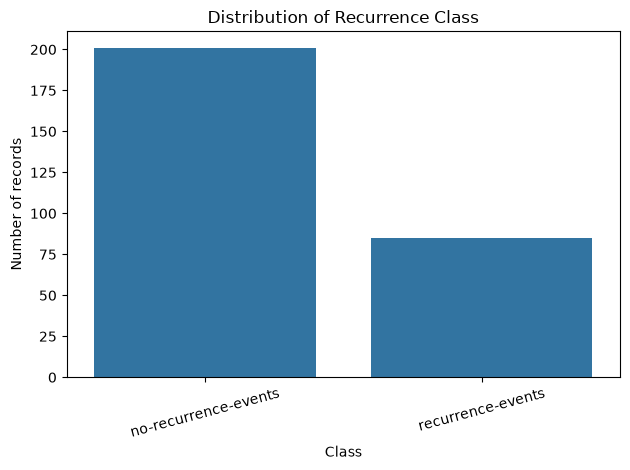

Class proportions:


,percent
Class,
no-recurrence-events,70.28
recurrence-events,29.72


In [13]:
# Class distribution
class_counts = df["Class"].value_counts()
display(class_counts.to_frame("count"))

ax = sns.countplot(data=df, x="Class", order=class_counts.index)
ax.set_title("Distribution of Recurrence Class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Class proportions:")
display((df["Class"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

# 2. Aggregation and Cross-tabulation

Compare recurrence counts across selected attributes. These are descriptive associations, not evidence that an attribute causes recurrence.

Class,no-recurrence-events,recurrence-events,All
deg-malig,,,
1,59,12,71
2,102,28,130
3,40,45,85
All,201,85,286


Class,no-recurrence-events,recurrence-events
irradiat,,
no,0.752,0.248
yes,0.544,0.456


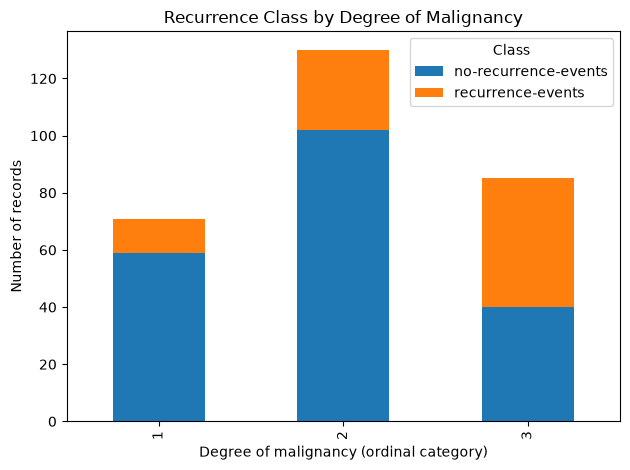

In [14]:
# Recurrence class by degree of malignancy
display(pd.crosstab(df["deg-malig"], df["Class"], margins=True))

# Recurrence class by irradiation status
display(pd.crosstab(df["irradiat"], df["Class"], normalize="index").round(3))

# Visualize recurrence counts by degree of malignancy
ct = pd.crosstab(df["deg-malig"], df["Class"])
ct.plot(kind="bar", stacked=True)
plt.title("Recurrence Class by Degree of Malignancy")
plt.xlabel("Degree of malignancy (ordinal category)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# 3. Classification: Predict Recurrence

**Goal:** predict `Class` from the other attributes. Use a train/test split and a pipeline so missing-value handling and one-hot encoding are learned from the training set only. Compare a Logistic Regression model with a Decision Tree.

The dataset is small and imbalanced, so report precision, recall, F1-score and balanced accuracy—not accuracy alone. This is a learning exercise, not a clinical prediction tool.


Logistic Regression
                      precision    recall  f1-score   support

no-recurrence-events       0.83      0.67      0.74        51
   recurrence-events       0.45      0.67      0.54        21

            accuracy                           0.67        72
           macro avg       0.64      0.67      0.64        72
        weighted avg       0.72      0.67      0.68        72



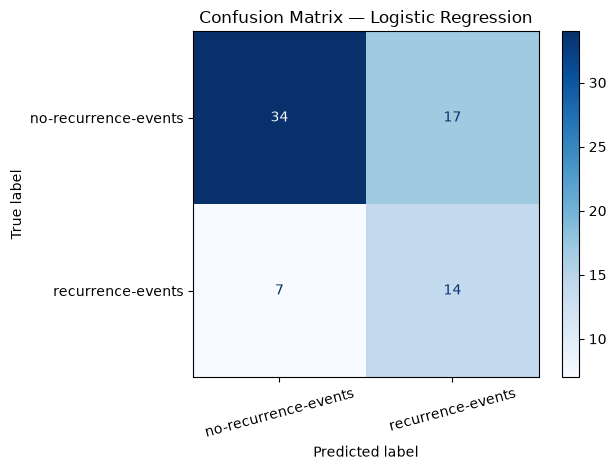


Decision Tree
                      precision    recall  f1-score   support

no-recurrence-events       0.78      0.61      0.68        51
   recurrence-events       0.38      0.57      0.45        21

            accuracy                           0.60        72
           macro avg       0.57      0.59      0.57        72
        weighted avg       0.66      0.60      0.61        72



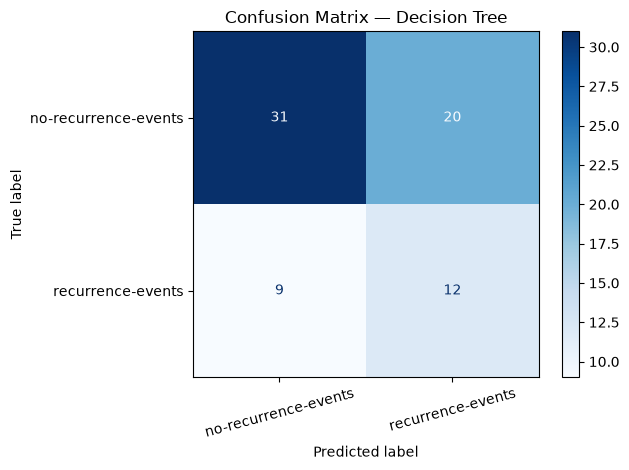

,model,balanced_accuracy,macro_F1
0,Logistic Regression,0.666667,0.638796
1,Decision Tree,0.589636,0.567074


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    balanced_accuracy_score, f1_score
)

# Use the original columns only; do not include engineered columns or target leakage.
X = df.drop(columns=["Class", "malignancy_category", "node_caps_flag",
                     "irradiat_flag", "recurrence"], errors="ignore")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), X.columns.tolist())
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=42, class_weight="balanced"
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "model": name,
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "macro_F1": f1_score(y_test, y_pred, average="macro")
    })
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, xticks_rotation=15, cmap="Blues"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).sort_values("macro_F1", ascending=False)
display(results_df)

## 4. Clustering Using Two Features

The original attributes are categorical/ordinal, so ordinary K-Means is not ideal for the full dataset. For a syllabus demonstration, select two ordered features (`age` and `tumor-size`), map their bins to ordinal numbers, standardize them, and run K-Means. **Do not use `Class` to create the clusters**; use it only afterward to colour/describe the plot if desired.

This is an approximation: the ordinal codes assume equal spacing between bins, which may not be true.

In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

age_order = ["20-29", "30-39", "40-49", "50-59", "60-69", "70-79"]
tumor_order = ["0-4", "5-9", "10-14", "15-19", "20-24",
               "25-29", "30-34", "35-39", "40-44", "45-49", "50-54"]

cluster_data = df[["age", "tumor-size"]].copy()
cluster_data["age_code"] = pd.Categorical(
    cluster_data["age"], categories=age_order, ordered=True
).codes
cluster_data["tumor_size_code"] = pd.Categorical(
    cluster_data["tumor-size"], categories=tumor_order, ordered=True
).codes

# Fail clearly if a value is not represented in the mappings.
if (cluster_data[["age_code", "tumor_size_code"]] < 0).any().any():
    raise ValueError("Unexpected age or tumor-size category; inspect unique values.")

features_2d = cluster_data[["age_code", "tumor_size_code"]].to_numpy()
scaled_2d = StandardScaler().fit_transform(features_2d)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(scaled_2d)
cluster_data["cluster"] = cluster_labels
print("Inertia (within-cluster sum of squares):", round(kmeans.inertia_, 3))
if len(set(cluster_labels)) > 1:
    print("Silhouette score:", round(silhouette_score(scaled_2d, cluster_labels), 3))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=cluster_data, x="age_code", y="tumor_size_code",
    hue="cluster", palette="Set2", s=70
)
plt.title("K-Means Clustering Using Age and Tumor-Size Categories")
plt.xlabel("Age category code (ordered)")
plt.ylabel("Tumor-size category code (ordered)")
plt.tight_layout()
plt.show()

# Describe the resulting clusters
cluster_summary = cluster_data.groupby("cluster").agg(
    records=("cluster", "size"),
    mean_age_code=("age_code", "mean"),
    mean_tumor_size_code=("tumor_size_code", "mean")
)
display(cluster_summary)

# Optional: after clustering, inspect recurrence composition per cluster (not used to fit clusters)
display(pd.crosstab(cluster_data["cluster"], df["Class"], normalize="index").round(3))

/tmp/ipykernel_534547/1885499715.py:13: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  cluster_data["tumor_size_code"] = pd.Categorical(


ValueError: Unexpected age or tumor-size category; inspect unique values.

## 5. Choosing k: Compare Cluster Counts

Compare K-Means solutions for several values of `k`. Inertia usually decreases as `k` increases, so also inspect the silhouette score. With only two ordinal-coded features and a small dataset, treat this as a demonstration rather than proof that natural patient groups exist.

In [17]:
k_values = range(2, 7)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(scaled_2d)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(scaled_2d, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Plot")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

NameError: name 'scaled_2d' is not defined

## 6. Association Rule Mining (Apriori)

Find combinations of attribute values that frequently occur together. One-hot encode each attribute-value pair, then use Apriori to find frequent itemsets and generate rules. `support` measures how often the whole combination occurs; `confidence` measures how often the consequent occurs when the antecedent occurs; `lift > 1` indicates a positive association compared with independence.

Install `mlxtend` if needed. The rules are descriptive associations, not causal or medical conclusions.

In [ ]:
# Run this once if mlxtend is not installed:
# %pip install mlxtend

from mlxtend.frequent_patterns import apriori, association_rules

# Build item indicators from categorical values.
# Include Class so rules can describe associations with recurrence class.
transaction_data = df[[
    "Class", "age", "menopause", "tumor-size", "inv-nodes",
    "node-caps", "deg-malig", "breast", "breast-quad", "irradiat"
]].astype(str)

onehot = pd.get_dummies(transaction_data, prefix=transaction_data.columns,
                        prefix_sep="=").astype(bool)

frequent_itemsets = apriori(
    onehot, min_support=0.08, use_colnames=True, max_len=4
).sort_values("support", ascending=False)

print("Frequent itemsets found:", len(frequent_itemsets))
display(frequent_itemsets.head(15))

rules = association_rules(
    frequent_itemsets, metric="confidence", min_threshold=0.6
)

if not rules.empty:
    rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
    # Prefer rules whose consequent is a recurrence class.
    recurrence_rules = rules[
        rules["consequents"].str.contains("Class=recurrence-events|Class=no-recurrence-events",
                                          regex=True)
    ].sort_values(["lift", "confidence"], ascending=False)

    display(recurrence_rules[[
        "antecedents", "consequents", "support", "confidence", "lift"
    ]].head(20))
else:
    print("No rules met the selected thresholds. Try a lower min_support or confidence threshold.")

## 7. Feature Association: Chi-square Test and Cramér's V

Since most features are categorical, Pearson correlation is generally not the right measure for their relationships. Use a chi-square test of independence and Cramér's V for selected pairs. A low p-value suggests evidence of association in this sample; it does not imply causation. Some cells may have low expected counts, so interpret p-values cautiously.

In [ ]:
from scipy.stats import chi2_contingency
import math

def cramers_v(contingency_table):
    chi2 = chi2_contingency(contingency_table, correction=False)[0]
    n = contingency_table.to_numpy().sum()
    r, k = contingency_table.shape
    denom = n * min(r - 1, k - 1)
    return math.sqrt(chi2 / denom) if denom > 0 else np.nan

pairs = [
    ("deg-malig", "Class"),
    ("irradiat", "Class"),
    ("age", "Class"),
    ("tumor-size", "Class"),
    ("node-caps", "Class")
]

association_results = []
for feature, target in pairs:
    table = pd.crosstab(df[feature], df[target])
    chi2, p_value, dof, expected = chi2_contingency(table)
    association_results.append({
        "feature": feature,
        "target": target,
        "chi2": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "cramers_v": cramers_v(table),
        "minimum_expected_count": expected.min()
    })

association_df = pd.DataFrame(association_results).sort_values("cramers_v", ascending=False)
display(association_df.round(4))

## 8. Similarity and Dissimilarity Between Two Patient Records

For categorical attributes, simple matching dissimilarity is the proportion of selected attributes that differ. This avoids treating arbitrary category labels as numeric distances. The example compares two rows using the original categorical attributes; it is a direct demonstration of a similarity/dissimilarity measure.

In [ ]:
similarity_features = [
    "age", "menopause", "tumor-size", "inv-nodes",
    "node-caps", "deg-malig", "breast", "breast-quad", "irradiat"
]

record_a = df.iloc[0][similarity_features]
record_b = df.iloc[1][similarity_features]

matches = (record_a == record_b)
matching_count = int(matches.sum())
total_features = len(similarity_features)
simple_matching_similarity = matching_count / total_features
simple_matching_dissimilarity = 1 - simple_matching_similarity

comparison = pd.DataFrame({
    "record_1": record_a,
    "record_2": record_b,
    "match": matches
})
display(comparison)
print(f"Matching attributes: {matching_count}/{total_features}")
print(f"Simple matching similarity: {simple_matching_similarity:.3f}")
print(f"Simple matching dissimilarity: {simple_matching_dissimilarity:.3f}")

## 9. Outlier / Rare-Combination Inspection

For categorical data, rare combinations are often more interpretable than applying a numeric outlier algorithm directly to arbitrary category codes. This identifies infrequent combinations of selected attributes for inspection; it does not label them as errors or clinically abnormal.

In [ ]:
rare_features = ["age", "tumor-size", "inv-nodes", "deg-malig", "Class"]
combo_counts = (
    df.groupby(rare_features, dropna=False)
      .size()
      .reset_index(name="combination_count")
      .sort_values("combination_count")
)

display(combo_counts.head(15))
print("These are infrequent combinations, not necessarily data errors.")

NameError: name 'df' is not defined

# 10. Suggested Conclusion Template

After running the notebook, write the conclusion from your actual outputs:

- **Preprocessing:** report the original number of records, missing values, and how missing categorical values were handled.
- **EDA / aggregation:** mention which categories show different recurrence proportions, without claiming causation.
- **Classification:** compare the test-set macro-F1 and balanced accuracy for Logistic Regression and Decision Tree. Note that a single split on 286 records is unstable.
- **Clustering:** report the selected features, chosen `k`, inertia/silhouette, and what the clusters look like. Explain the limitation of ordinal-encoding categories.
- **Association rules:** report a few high-support rules with support, confidence and lift; do not describe them as medical facts.
- **Feature association:** summarize chi-square/Cramér's V results and note small expected counts where relevant.
- **Limitations:** small historical dataset, coarse categorical bins, imbalanced target, and no clinical use. Do not invent conclusions before examining the output.